In [42]:
import numpy as np
import matplotlib.pyplot as plt

In [43]:
rng = np.random.default_rng(42)

# Part 1

| Model            | How is \(J_t\) chosen?                                        | Interpretation                                      |
| ---------------- | ------------------------------------------------------------- | --------------------------------------------------- |
| **SETAR(2;1;1)** | Determined by a threshold on a lagged \(X\), e.g. \(X_{t-1}\) | Regime depends on the observed state of the process |
| **IGAR(2;1)**    | Drawn randomly with fixed probabilities \(p_1,p_2\)           | Regime is random and independent over time          |
| **MMAR(2;1)**    | Drawn from a Markov chain using \(J_{t-1}\)                   | Regime depends on the previous regime               |


### SETAR model

In [44]:
l = 2 #Regimes
d = 1 # Delay
k = 1 # AR lag in each regime

In [45]:
import numpy as np


def SETAR(X, threshold, a, eps):
    """
    Two-regime SETAR(2, 1, 1) model.

    X[t] = a0^(J_t) + a1^(J_t) * X[t-1] + eps[t]

    Regime 1:
        X[t-1] < threshold

    Regime 2:
        X[t-1] >= threshold
    """

    for t in range(1, len(X)):

        if X[t - 1] < threshold:
            X[t] = (
                a[0][0]
                + a[0][1] * X[t - 1]
                + eps[t]
            )

        else:
            X[t] = (
                a[1][0]
                + a[1][1] * X[t - 1]
                + eps[t]
            )

    return X

In [46]:
n = 100

eps = rng.normal(0, 1, n)

X = np.zeros(n)
X[0] = eps[0]

a = [
    [4, 0.5],      # Regime 1
    [-4, -0.5]     # Regime 2
]

X = SETAR(
    X=X,
    threshold=0,
    a=a,
    eps=eps
)



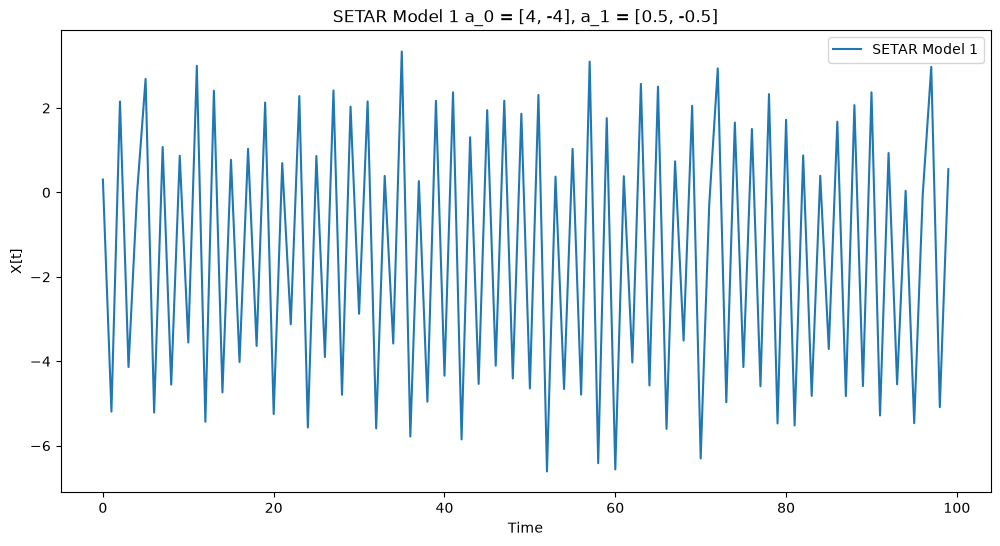

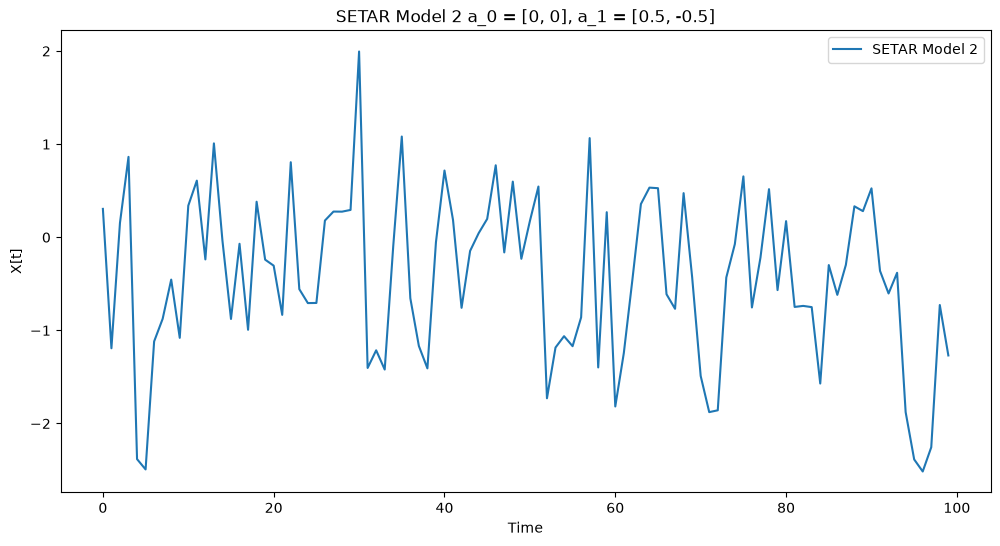

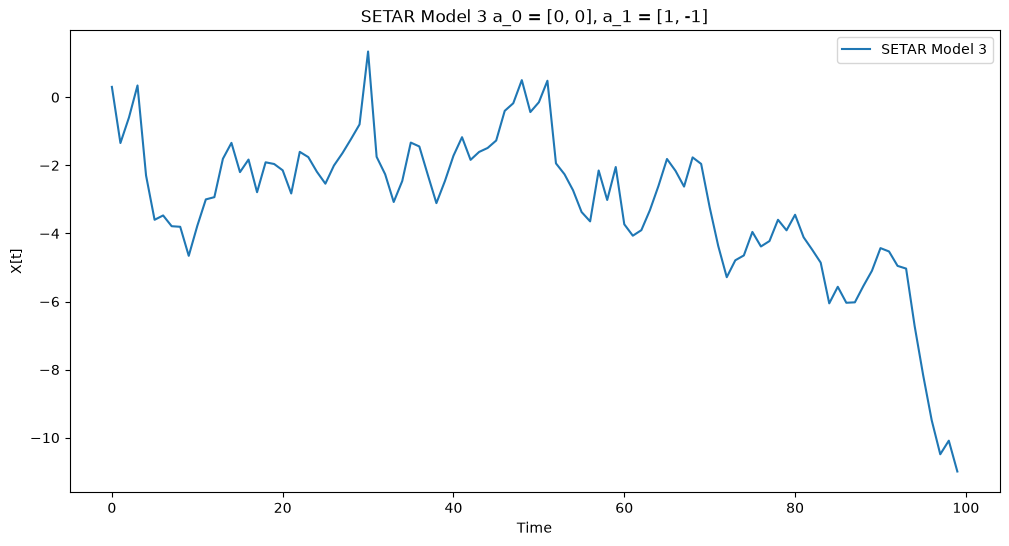

In [47]:
a_dict = {
    1: [
        [4, 0.5],      # Regime 1
        [-4, -0.5]     # Regime 2
    ],
    2: [
        [0, 0.5],      # Regime 1
        [0, -0.5]      # Regime 2
    ],
    3: [
        [0, 1],      # Regime 1
        [0, -1]      # Regime 2
    ]
}

names_dict = {
    1: 'SETAR Model 1 a_0 = [4, -4], a_1 = [0.5, -0.5]',
    2: 'SETAR Model 2 a_0 = [0, 0], a_1 = [0.5, -0.5]',
    3: 'SETAR Model 3 a_0 = [0, 0], a_1 = [1, -1]'
}

for i in range (1, 4):
    a = a_dict[i]
    X = SETAR(
        X=X,
        threshold=0,
        a=a,
        eps=eps
    )

    # Plot the time series
    plt.figure(figsize=(12, 6))
    plt.plot(X, label=f'SETAR Model {i}')
    plt.title(names_dict[i])
    plt.xlabel('Time')
    plt.ylabel('X[t]')
    plt.legend()
    plt.savefig(f'assets/1_setar_{i}.png')  # Save the figure as a PNG file
    plt.show()

### IGAR(2;1)

In [48]:
def IGAR(X, l, k, p, a, eps):
    """
    Simulate an IGAR model:

        X_t = a_0^(J_t)
              + sum_{i=1}^{k_Jt} a_i^(J_t) X_{t-i}
              + eps_t^(J_t)

    where

        P(J_t = j) = p_j
    """

    start = max(k)

    for t in range(start, len(X)):

        # Randomly choose regime J_t
        J_t = np.random.choice(
            np.arange(l),
            p=p
        )

        # Intercept for the chosen regime
        X[t] = a[J_t][0]

        # AR part
        for i in range(1, k[J_t] + 1):
            X[t] += a[J_t][i] * X[t - i]

        # Error term
        X[t] += eps[t]

    return X

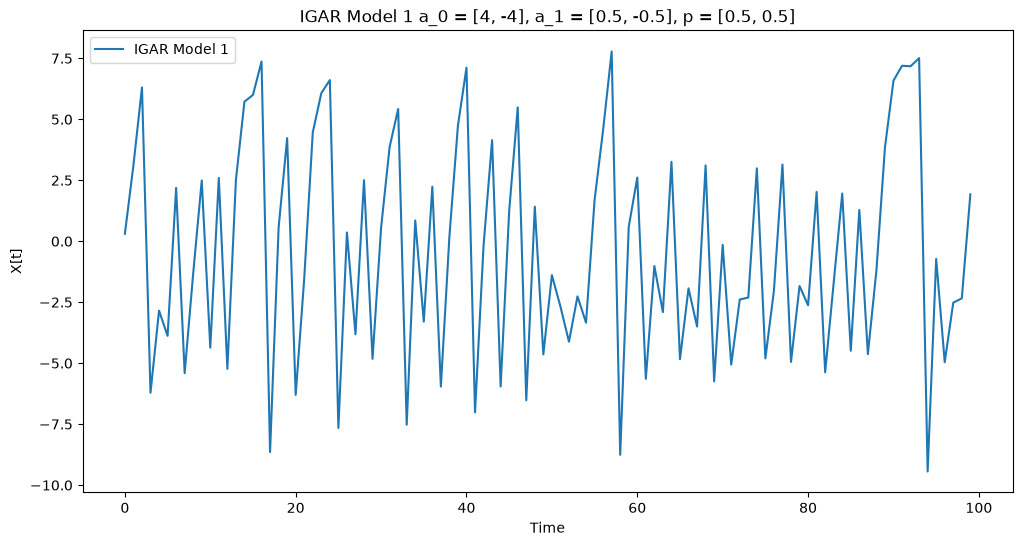

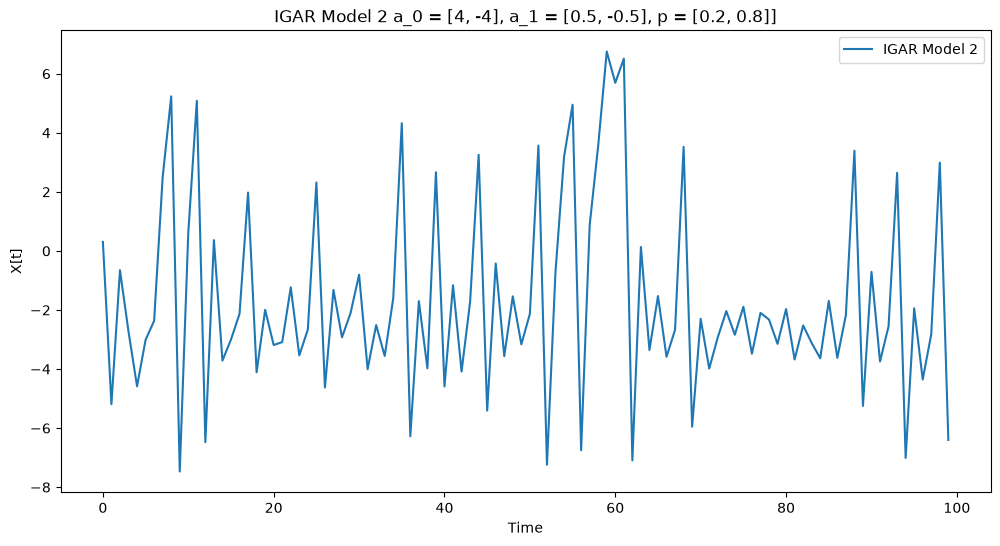

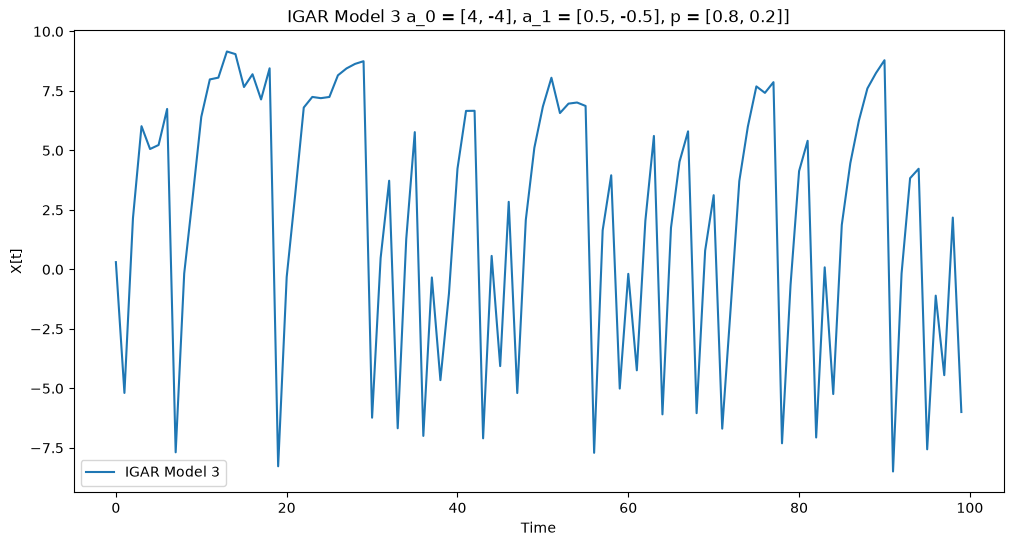

In [49]:
a_dict = {
    1: [
        [4, 0.5],      # Regime 1
        [-4, -0.5]     # Regime 2
    ],
    2: [
        [4, 0.5],      # Regime 1
        [-4, -0.5]     # Regime 2
    ],
    3: [
        [4, 0.5],      # Regime 1
        [-4, -0.5]     # Regime 2
    ]
}

probability_dict = {
    1: [0.5, 0.5],
    2: [0.2, 0.8],
    3: [0.8, 0.2]
}

names_dict = {
    1: 'IGAR Model 1 a_0 = [4, -4], a_1 = [0.5, -0.5], p = [0.5, 0.5]',
    2: 'IGAR Model 2 a_0 = [4, -4], a_1 = [0.5, -0.5], p = [0.2, 0.8]]',
    3: 'IGAR Model 3 a_0 = [4, -4], a_1 = [0.5, -0.5], p = [0.8, 0.2]]'
}

# Probability of each regime
p = [0.5, 0.5]

for i in range(1, 4):

    a = a_dict[i]
    p = probability_dict[i]

    # Reset X for every simulation
    X = np.zeros(n)
    X[0] = eps[0]

    X = IGAR(
        X=X,
        l=2,
        k=[1, 1],
        p=p,
        a=a,
        eps=eps
    )

    # Plot the time series
    plt.figure(figsize=(12, 6))
    plt.plot(X, label=f'IGAR Model {i}')

    plt.title(names_dict[i])
    plt.xlabel('Time')
    plt.ylabel('X[t]')

    plt.legend()
    plt.savefig(f'assets/2_igar_{i}.png')
    plt.show()

### IGAR(2;1)

In [50]:
import numpy as np


def MMAR(X, k, P, a, eps, initial_regime=0):
    """
    Simulate an MMAR(2, 1) model.

    X_t = a_0^(J_t)
          + sum_{i=1}^{k_Jt} a_i^(J_t) X_{t-i}
          + eps_t

    The regime J_t follows a Markov chain with
    transition matrix P.
    """

    start = max(k)

    # Store regimes
    J = np.zeros(len(X), dtype=int)

    # Initial regime
    J[0] = initial_regime

    for t in range(start, len(X)):

        # Draw current regime based on previous regime
        J[t] = np.random.choice(
            [0, 1],
            p=P[J[t - 1]]
        )

        # Intercept
        X[t] = a[J[t]][0]

        # AR part
        for i in range(1, k[J[t]] + 1):
            X[t] += a[J[t]][i] * X[t - i]

        # Error
        X[t] += eps[t]

    return X, J

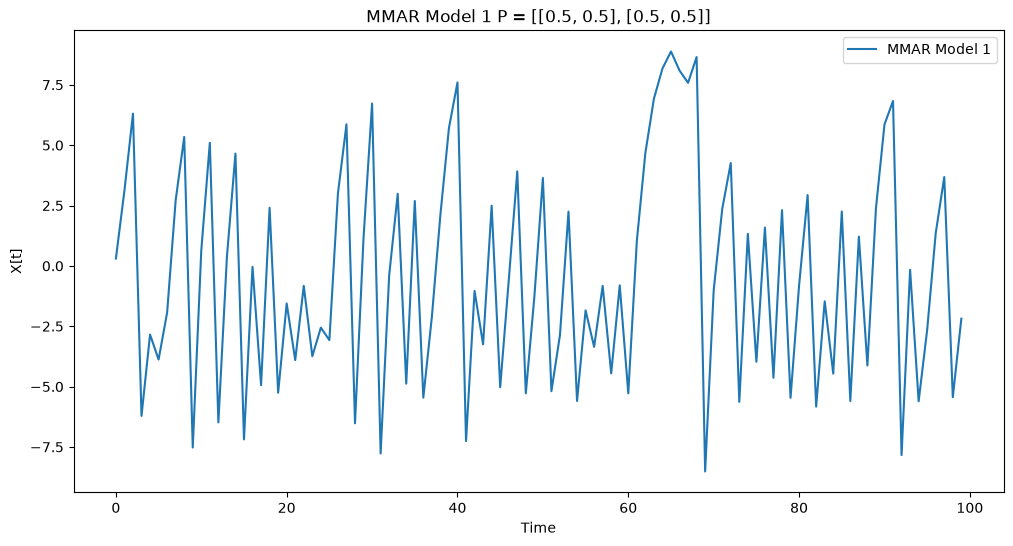

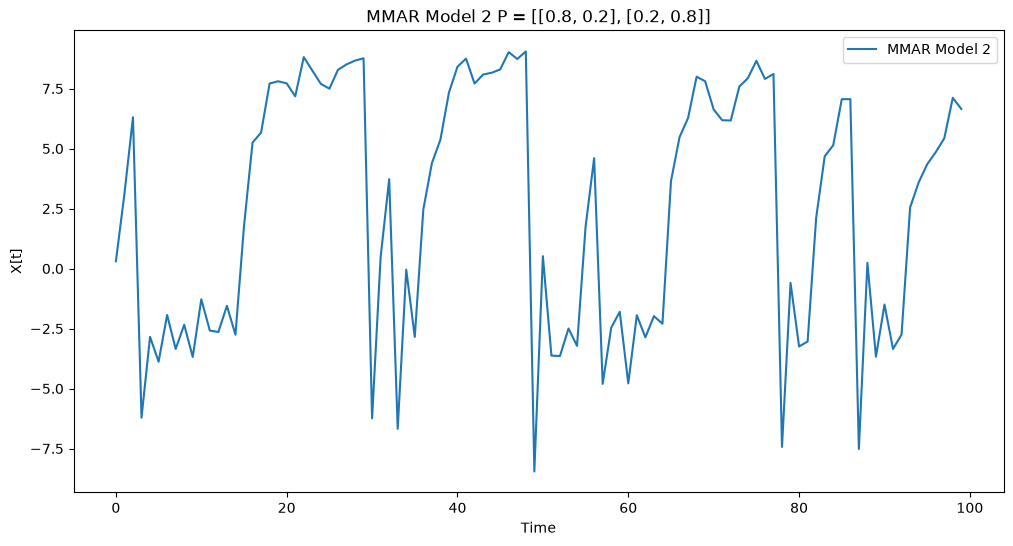

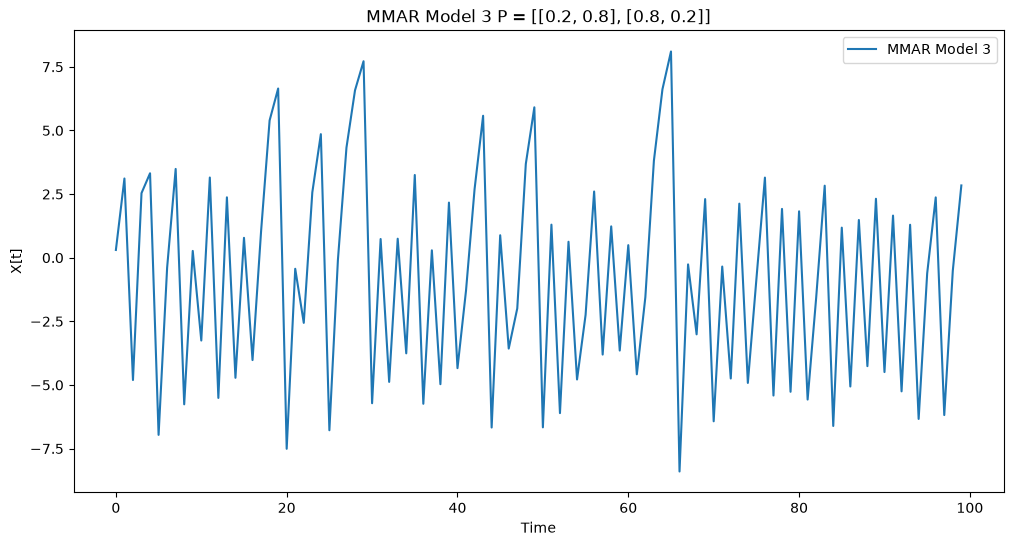

In [51]:
a_dict = {
    1: [
        [4, 0.5],      # Regime 1
        [-4, -0.5]     # Regime 2
    ],
    2: [
        [4, 0.5],
        [-4, -0.5]
    ],
    3: [
        [4, 0.5],
        [-4, -0.5]
    ]
}

transition_dict = {
    1: np.array([
        [0.5, 0.5],
        [0.5, 0.5]
    ]),

    2: np.array([
        [0.8, 0.2],
        [0.2, 0.8]
    ]),

    3: np.array([
        [0.2, 0.8],
        [0.8, 0.2]
    ])
}

names_dict = {
    1: 'MMAR Model 1 P = [[0.5, 0.5], [0.5, 0.5]]',
    2: 'MMAR Model 2 P = [[0.8, 0.2], [0.2, 0.8]]',
    3: 'MMAR Model 3 P = [[0.2, 0.8], [0.8, 0.2]]'
}

for i in range(1, 4):

    a = a_dict[i]
    P = transition_dict[i]

    # Reset X for every simulation
    X = np.zeros(n)
    X[0] = eps[0]

    X, J = MMAR(
        X=X,
        k=[1, 1],
        P=P,
        a=a,
        eps=eps
    )

    # Plot the time series
    plt.figure(figsize=(12, 6))
    plt.plot(X, label=f'MMAR Model {i}')

    plt.title(names_dict[i])
    plt.xlabel('Time')
    plt.ylabel('X[t]')

    plt.legend()
    plt.savefig(f'assets/3_mmar_{i}.png')
    plt.show()